NOTEBOOK 11 — SHAP EXPLAINABILITY

Configuration:
Random State: 42
Test Size: 0.2
SHAP Output Directory: shap_explainability_results
Notebook 10 Optimal Threshold: 0.21

DATASET LOADED

Dataset Shape: (10000, 45)

DATA VALIDATION

Missing Values: 0
Duplicate Rows: 0

Target Distribution:
churn
0    8979
1    1021
Name: count, dtype: int64

Target Distribution (%):
churn
0    89.79
1    10.21
Name: proportion, dtype: float64

FEATURES AND TARGET

Feature Shape: (10000, 44)
Target Shape: (10000,)

Number of Predictor Variables: 44

TRAIN / TEST SPLIT

Training Shape: (8000, 44)
Testing Shape: (2000, 44)

Training Target Distribution:
churn
0    7183
1     817
Name: count, dtype: int64

Testing Target Distribution:
churn
0    1796
1     204
Name: count, dtype: int64

LOADING FINAL COST-SENSITIVE MODEL

Final model loaded successfully.

Model Type:
<class 'imblearn.pipeline.Pipeline'>

MODEL PIPELINE

Pipeline steps:
 - preprocessing: ColumnTransformer
 - smote: SMOTE
 - model: XGBClassifi

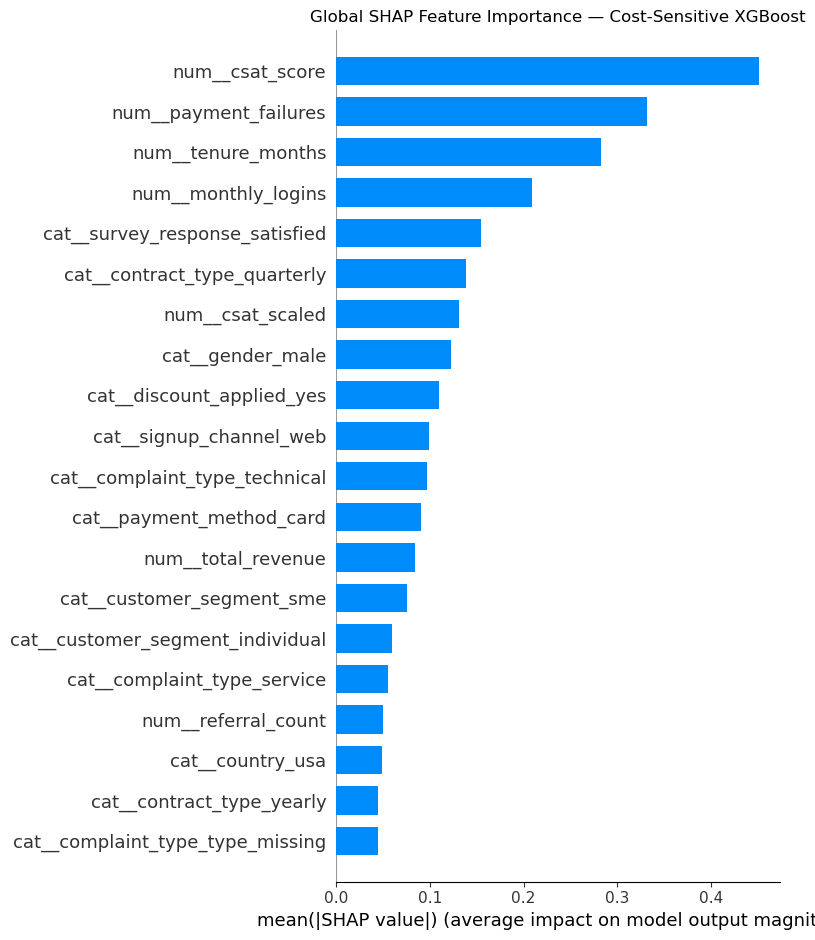


PLOT 2 — SHAP BEESWARM SUMMARY


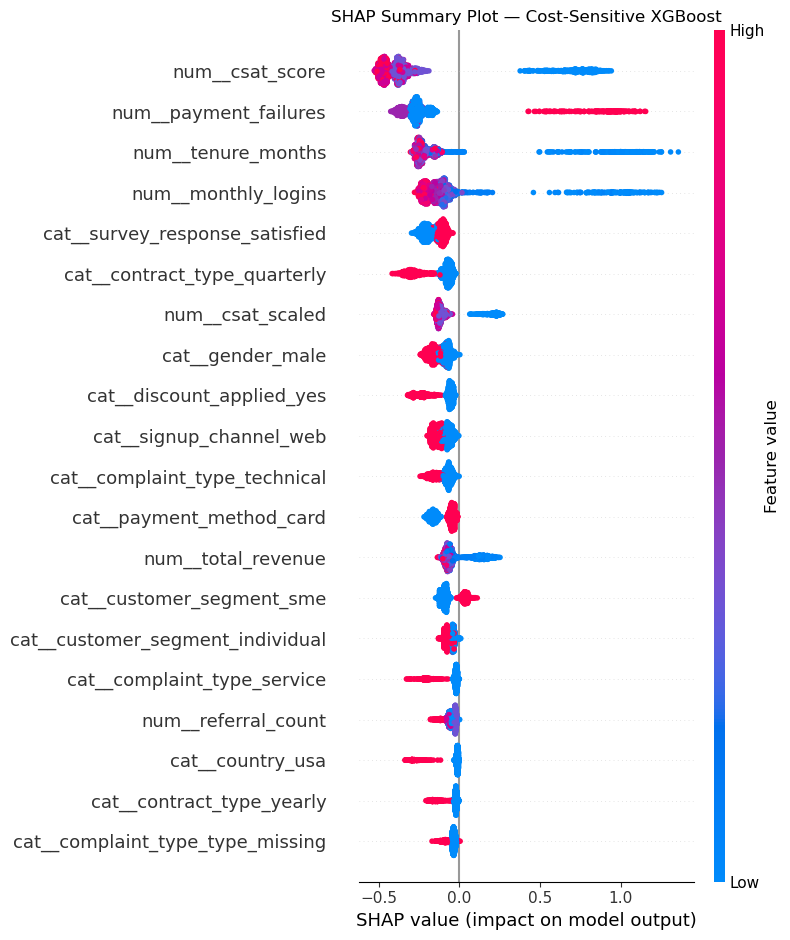


TOP 10 SHAP FEATURES
   Rank                         Feature  Mean_Absolute_SHAP  Mean_SHAP
0     1                 num__csat_score            0.450743  -0.225254
1     2           num__payment_failures            0.331749  -0.168797
2     3              num__tenure_months            0.281920  -0.114419
3     4             num__monthly_logins            0.208815  -0.053816
4     5  cat__survey_response_satisfied            0.154903  -0.154903
5     6    cat__contract_type_quarterly            0.138498  -0.138498
6     7                num__csat_scaled            0.131429  -0.067635
7     8                cat__gender_male            0.122070  -0.122067
8     9       cat__discount_applied_yes            0.109214  -0.109214
9    10         cat__signup_channel_web            0.099430  -0.099430

FEATURE DIRECTION ANALYSIS

Features with strongest average positive influence:
Empty DataFrame
Columns: [Feature, Mean_Absolute_SHAP, Mean_SHAP]
Index: []

Features with strongest average negativ

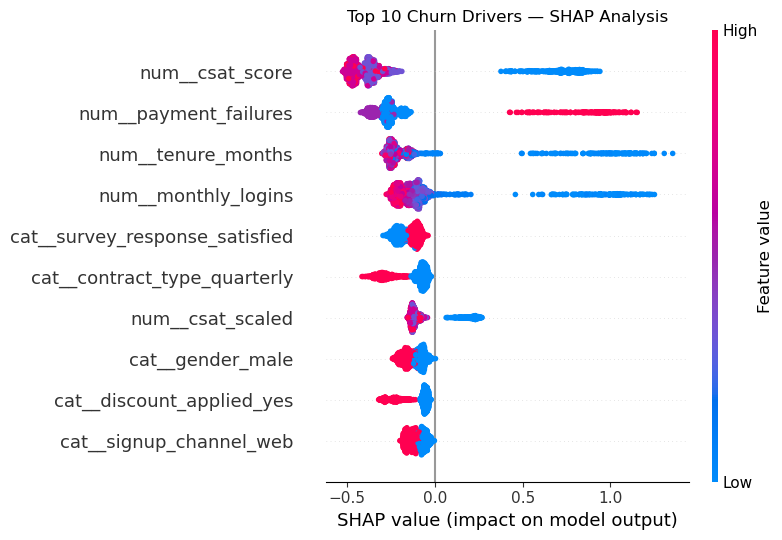


DEPENDENCE PLOTS — TOP 3 FEATURES

Top 3 features:
 - num__csat_score
 - num__payment_failures
 - num__tenure_months


<Figure size 900x600 with 0 Axes>

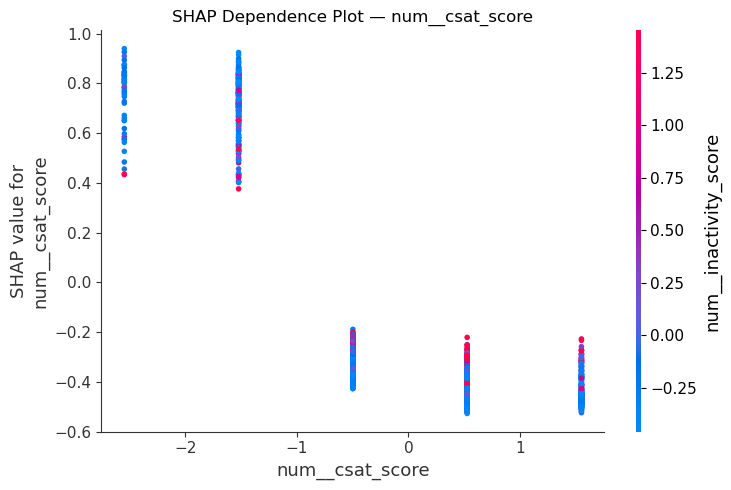

<Figure size 900x600 with 0 Axes>

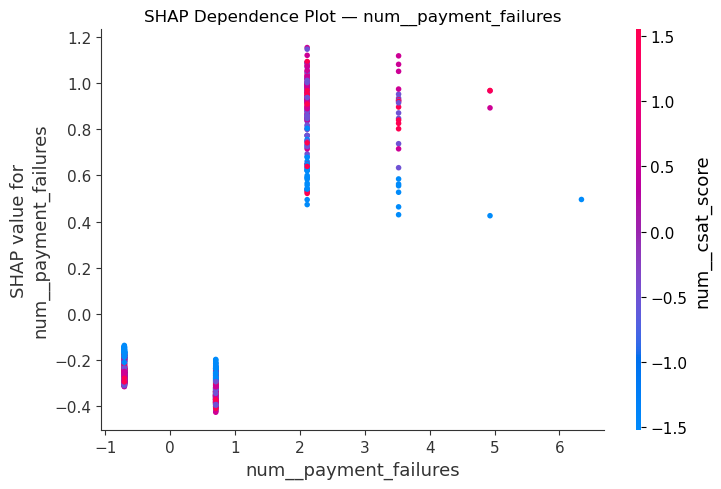

<Figure size 900x600 with 0 Axes>

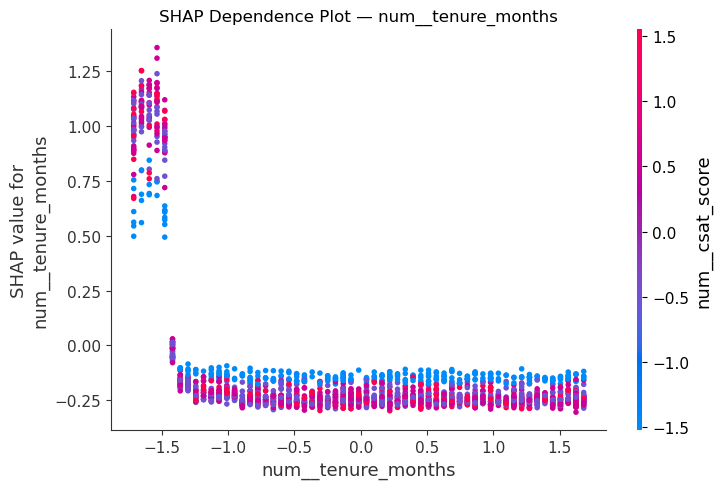


CREATING CUSTOMER SHAP EXPLANATION DATA

Customer SHAP dataset shape: (2000, 68)

Customer-level SHAP values saved.

HIGH-RISK CUSTOMER ANALYSIS

Number of high-risk customers: 725
Percentage of test customers classified as high risk: 36.25%

Number of low-risk customers: 1275

HIGHEST-RISK CUSTOMER

Customer Index: 7693
Predicted Churn Probability: 0.7627
Predicted Class: 1
Actual Churn: 0

LOWEST-RISK CUSTOMER

Customer Index: 6360
Predicted Churn Probability: 0.0321
Predicted Class: 0
Actual Churn: 0

HIGHEST-RISK CUSTOMER SHAP EXPLANATION

Customer Index: 7693
Predicted Churn Probability: 0.7627
Classification Threshold: 0.21
Predicted Class: 1
Actual Churn: 0

Top factors increasing churn prediction:
                   Feature  Feature_Value  SHAP_Value
1       num__tenure_months      -1.534152    0.887201
2      num__monthly_logins      -1.604990    0.745350
9       num__total_revenue      -0.915557    0.134158
23  num__revenue_per_login       0.460100    0.070165
30   num__inac

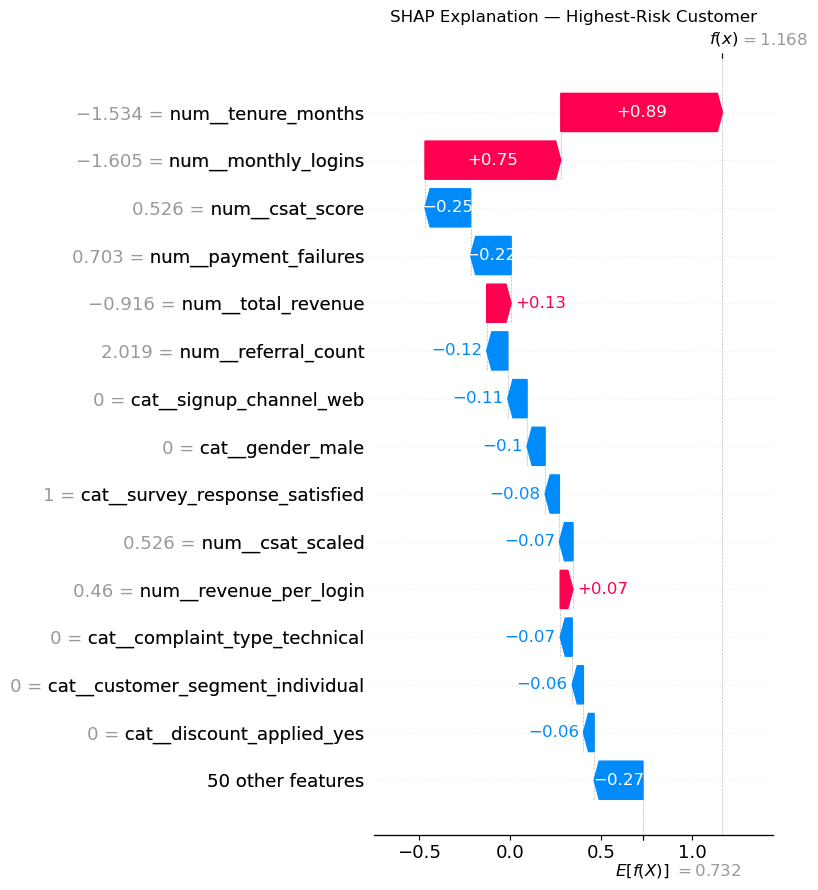


PLOT 5 — LOWEST-RISK CUSTOMER


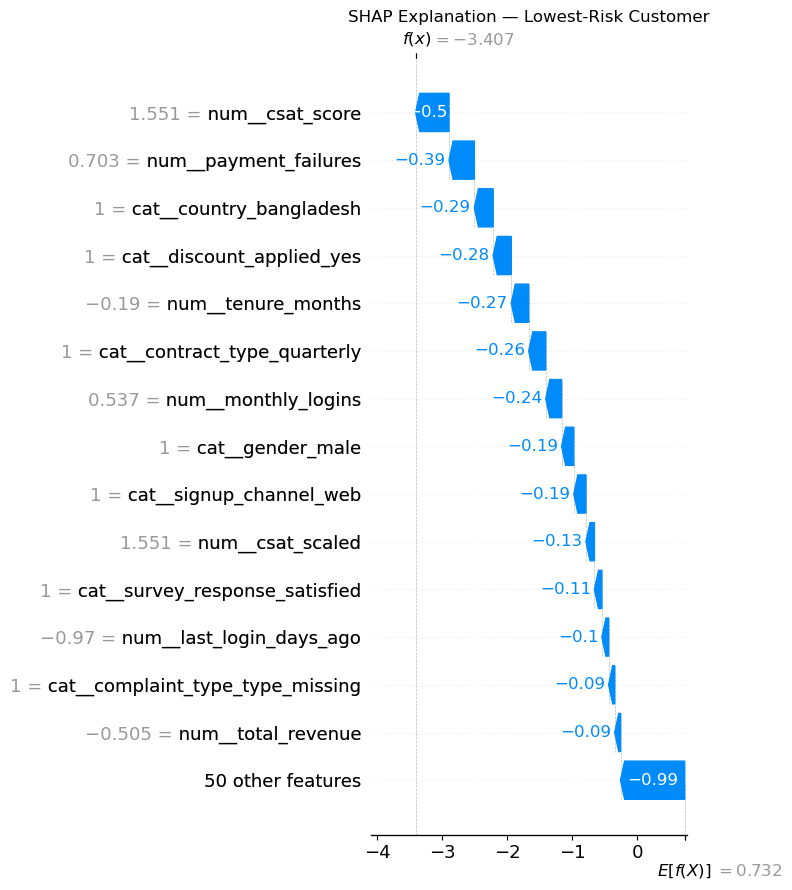


CUSTOMER-LEVEL SHAP SUMMARY
 Customer_Index Risk_Category  Actual_Churn  Predicted_Probability  Predicted_Class                                                                                           Top_Positive_SHAP_Features                                                                                     Top_Negative_SHAP_Features
           7693  Highest Risk             0               0.762697                1           num__tenure_months; num__monthly_logins; num__total_revenue; num__revenue_per_login; num__inactivity_score         num__csat_score; num__payment_failures; num__referral_count; cat__signup_channel_web; cat__gender_male
           6360   Lowest Risk             0               0.032079                0 num__complaint_ratio; num__email_open_rate; num__marketing_click_rate; num__avg_session_time; num__usage_growth_rate num__csat_score; num__payment_failures; cat__country_bangladesh; cat__discount_applied_yes; num__tenure_months

AGGREGATING SHAP IMPORTANCE TO ORI

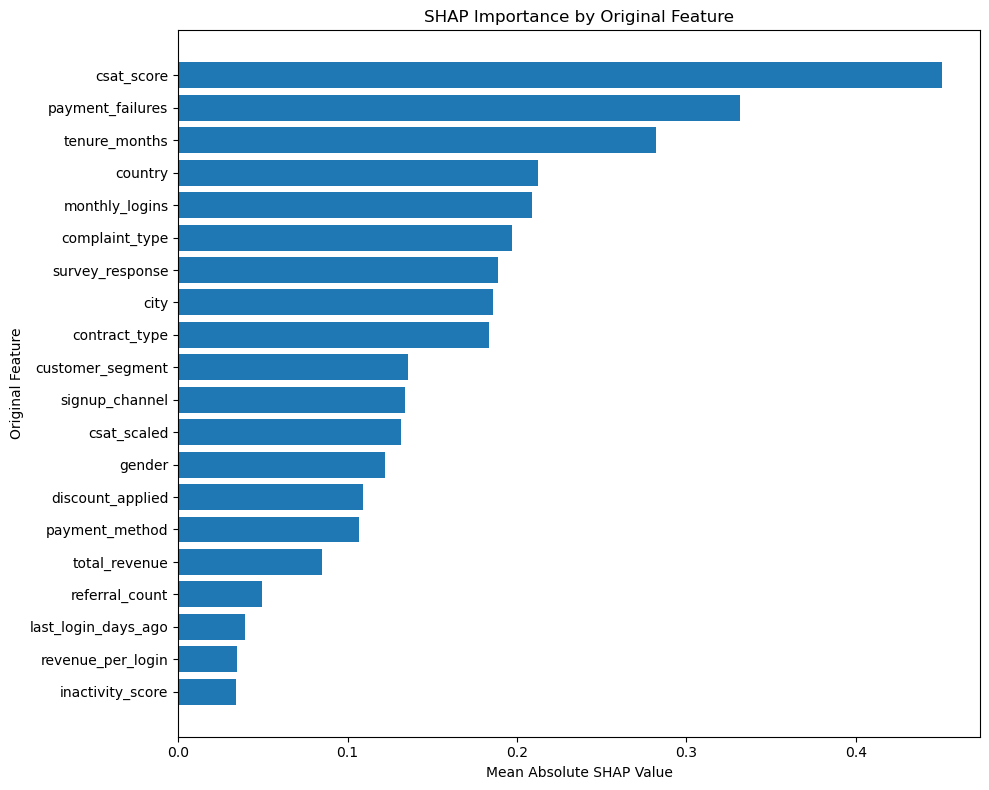


SHAP EXPLAINABILITY SUMMARY

Model Explained:
Cost-Sensitive XGBoost

SHAP Method:
TreeExplainer

Test Samples Explained: 2000
Original Predictor Variables: 44
Transformed Predictor Variables: 64

Optimal Classification Threshold: 0.21

High-Risk Customers: 725
Low-Risk Customers: 1275

Top 10 Original Features by SHAP Importance:
 Rank Original_Feature  Mean_Absolute_SHAP  Mean_SHAP
    1       csat_score            0.450743  -0.225254
    2 payment_failures            0.331749  -0.168797
    3    tenure_months            0.281920  -0.114419
    4          country            0.212348  -0.209229
    5   monthly_logins            0.208815  -0.053816
    6   complaint_type            0.196820  -0.196815
    7  survey_response            0.188942  -0.177547
    8             city            0.185563  -0.184459
    9    contract_type            0.183637  -0.183637
   10 customer_segment            0.135525  -0.114177

SAVED SHAP OUTPUTS
 - Customer_SHAP_Values.csv
 - Final_SHAP_Summary.cs

In [2]:
# ======================================================================
# NOTEBOOK 11 — SHAP EXPLAINABILITY
# ======================================================================



# ======================================================================
# 1. LIBRARIES
# ======================================================================

import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")


# ======================================================================
# 2. CONFIGURATION
# ======================================================================

RANDOM_STATE = 42
TEST_SIZE = 0.20

DATA_PATH = "customer_churn_feature_engineered.csv"

MODEL_DIR = "cost_sensitive_model_results"

MODEL_PATH = os.path.join(
    MODEL_DIR,
    "Best_Cost_Sensitive_XGBoost.pkl"
)

OUTPUT_DIR = "shap_explainability_results"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

# Threshold selected in Notebook 10
OPTIMAL_THRESHOLD = 0.21

# Number of top features to display
TOP_N_FEATURES = 20

# Number of individual examples to explain
N_HIGH_RISK = 1
N_LOW_RISK = 1


print("=" * 70)
print("NOTEBOOK 11 — SHAP EXPLAINABILITY")
print("=" * 70)

print("\nConfiguration:")
print(f"Random State: {RANDOM_STATE}")
print(f"Test Size: {TEST_SIZE}")
print(f"SHAP Output Directory: {OUTPUT_DIR}")
print(f"Notebook 10 Optimal Threshold: {OPTIMAL_THRESHOLD}")


# ======================================================================
# 3. LOAD DATASET
# ======================================================================

df = pd.read_csv(
    DATA_PATH
)

print("\n" + "=" * 70)
print("DATASET LOADED")
print("=" * 70)

print(f"\nDataset Shape: {df.shape}")


# ======================================================================
# 4. DATA VALIDATION
# ======================================================================

print("\n" + "=" * 70)
print("DATA VALIDATION")
print("=" * 70)

missing_values = df.isnull().sum().sum()
duplicate_rows = df.duplicated().sum()

print(f"\nMissing Values: {missing_values}")
print(f"Duplicate Rows: {duplicate_rows}")

print("\nTarget Distribution:")
print(df["churn"].value_counts())

print("\nTarget Distribution (%):")
print(
    df["churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


# ======================================================================
# 5. FEATURES AND TARGET
# ======================================================================

X = df.drop(
    columns=["churn"]
)

y = df["churn"]

print("\n" + "=" * 70)
print("FEATURES AND TARGET")
print("=" * 70)

print(f"\nFeature Shape: {X.shape}")
print(f"Target Shape: {y.shape}")

print(f"\nNumber of Predictor Variables: {X.shape[1]}")


# ======================================================================
# 6. RECREATE TRAIN / TEST SPLIT
# ======================================================================
#
# The same random state and test size used in Notebook 10 are used
# here so that the same test observations are analysed.
#
# SHAP analysis is performed on the unseen test data.
#
# ======================================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE
)

print("\n" + "=" * 70)
print("TRAIN / TEST SPLIT")
print("=" * 70)

print(f"\nTraining Shape: {X_train.shape}")
print(f"Testing Shape: {X_test.shape}")

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())


# ======================================================================
# 7. LOAD FINAL COST-SENSITIVE MODEL
# ======================================================================

print("\n" + "=" * 70)
print("LOADING FINAL COST-SENSITIVE MODEL")
print("=" * 70)

if not os.path.exists(MODEL_PATH):

    raise FileNotFoundError(
        f"\nModel file not found:\n{MODEL_PATH}\n\n"
        "Please run Notebook 10 first."
    )

final_model = joblib.load(
    MODEL_PATH
)

print("\nFinal model loaded successfully.")

print(
    "\nModel Type:"
)

print(
    type(final_model)
)


# ======================================================================
# 8. INSPECT PIPELINE
# ======================================================================

print("\n" + "=" * 70)
print("MODEL PIPELINE")
print("=" * 70)

print("\nPipeline steps:")

for step_name, step_object in final_model.steps:

    print(
        f" - {step_name}: "
        f"{type(step_object).__name__}"
    )


# ======================================================================
# 9. EXTRACT FITTED COMPONENTS
# ======================================================================
#
# Notebook 10 pipeline:
#
# preprocessing
#       ↓
# SMOTE
#       ↓
# XGBoost
#
# For SHAP we DO NOT apply SMOTE to the test data.
#
# Instead:
#
# Raw X_test
#      ↓
# Fitted preprocessing
#      ↓
# Transformed X_test
#      ↓
# Trained XGBoost
#      ↓
# SHAP
#
# ======================================================================

fitted_preprocessor = (
    final_model
    .named_steps["preprocessing"]
)

xgb_model = (
    final_model
    .named_steps["model"]
)

print("\n" + "=" * 70)
print("MODEL COMPONENTS EXTRACTED")
print("=" * 70)

print(
    "\nPreprocessing component:"
)

print(
    type(fitted_preprocessor)
)

print(
    "\nXGBoost component:"
)

print(
    type(xgb_model)
)


# ======================================================================
# 10. MODEL PARAMETERS
# ======================================================================

print("\n" + "=" * 70)
print("XGBOOST MODEL PARAMETERS")
print("=" * 70)

print(
    f"\nn_estimators: "
    f"{xgb_model.get_params().get('n_estimators')}"
)

print(
    f"max_depth: "
    f"{xgb_model.get_params().get('max_depth')}"
)

print(
    f"learning_rate: "
    f"{xgb_model.get_params().get('learning_rate')}"
)

print(
    f"min_child_weight: "
    f"{xgb_model.get_params().get('min_child_weight')}"
)

print(
    f"subsample: "
    f"{xgb_model.get_params().get('subsample')}"
)

print(
    f"colsample_bytree: "
    f"{xgb_model.get_params().get('colsample_bytree')}"
)

print(
    f"scale_pos_weight: "
    f"{xgb_model.get_params().get('scale_pos_weight')}"
)


# ======================================================================
# 11. TRANSFORM TEST DATA
# ======================================================================
#
# IMPORTANT:
#
# The test data must only pass through the preprocessing component.
#
# We DO NOT call:
#
#     final_model.transform()
#
# and we DO NOT apply SMOTE to the test set.
#
# This ensures that SHAP explains predictions on the original
# unseen test observations.
#
# ======================================================================

print("\n" + "=" * 70)
print("TRANSFORMING TEST DATA")
print("=" * 70)

X_test_transformed = (
    fitted_preprocessor.transform(
        X_test
    )
)

print(
    f"\nTransformed Test Shape: "
    f"{X_test_transformed.shape}"
)


# ======================================================================
# 12. CONVERT SPARSE MATRIX TO DENSE
# ======================================================================
#
# OneHotEncoder can produce a sparse matrix.
#
# SHAP TreeExplainer works more reliably with a dense NumPy array
# for this workflow.
#
# ======================================================================

if hasattr(
    X_test_transformed,
    "toarray"
):

    X_test_shap = (
        X_test_transformed.toarray()
    )

else:

    X_test_shap = np.asarray(
        X_test_transformed
    )


print(
    f"\nSHAP Input Shape: "
    f"{X_test_shap.shape}"
)

print(
    f"SHAP Input Type: "
    f"{type(X_test_shap)}"
)


# ======================================================================
# 13. GET TRANSFORMED FEATURE NAMES
# ======================================================================

print("\n" + "=" * 70)
print("TRANSFORMED FEATURE NAMES")
print("=" * 70)

feature_names = (
    fitted_preprocessor
    .get_feature_names_out()
)

print(
    f"\nNumber of Transformed Features: "
    f"{len(feature_names)}"
)

print("\nFirst 20 transformed features:")

for feature in feature_names[:20]:

    print(
        f" - {feature}"
    )


# ======================================================================
# 14. CREATE SHAP DATAFRAME
# ======================================================================

X_test_shap_df = pd.DataFrame(
    X_test_shap,
    columns=feature_names,
    index=X_test.index
)

print("\n" + "=" * 70)
print("SHAP DATAFRAME CREATED")
print("=" * 70)

print(
    f"\nSHAP DataFrame Shape: "
    f"{X_test_shap_df.shape}"
)


# ======================================================================
# 15. VERIFY MODEL PREDICTIONS
# ======================================================================
#
# Generate probabilities directly from the loaded final pipeline.
#
# These predictions should correspond to the predictions produced
# by Notebook 10.
#
# ======================================================================

print("\n" + "=" * 70)
print("VERIFYING MODEL PREDICTIONS")
print("=" * 70)

test_probabilities = (
    final_model
    .predict_proba(X_test)[:, 1]
)

test_predictions = (
    test_probabilities >= OPTIMAL_THRESHOLD
).astype(int)

print(
    f"\nMean Predicted Churn Probability: "
    f"{test_probabilities.mean():.4f}"
)

print(
    f"Minimum Probability: "
    f"{test_probabilities.min():.4f}"
)

print(
    f"Maximum Probability: "
    f"{test_probabilities.max():.4f}"
)

print(
    f"\nPredicted Not Churn: "
    f"{(test_predictions == 0).sum()}"
)

print(
    f"Predicted Churn: "
    f"{(test_predictions == 1).sum()}"
)


# ======================================================================
# 16. CREATE SHAP TREE EXPLAINER
# ======================================================================

print("\n" + "=" * 70)
print("CREATING SHAP EXPLAINER")
print("=" * 70)

explainer = shap.TreeExplainer(
    xgb_model
)

print(
    "\nSHAP TreeExplainer created successfully."
)


# ======================================================================
# 17. CALCULATE SHAP VALUES
# ======================================================================
#
# SHAP values quantify the contribution of each feature to an
# individual prediction.
#
# Positive SHAP value:
# pushes prediction towards churn.
#
# Negative SHAP value:
# pushes prediction towards non-churn.
#
# Magnitude:
# indicates strength of contribution.
#
# ======================================================================

print("\n" + "=" * 70)
print("CALCULATING SHAP VALUES")
print("=" * 70)

shap_output = explainer(
    X_test_shap
)

print(
    "\nSHAP values calculated successfully."
)


# ======================================================================
# 18. HANDLE SHAP OUTPUT
# ======================================================================
#
# SHAP versions can return slightly different formats.
#
# The following code extracts the SHAP value matrix safely.
#
# ======================================================================

if hasattr(
    shap_output,
    "values"
):

    shap_values = (
        shap_output.values
    )

else:

    shap_values = (
        np.asarray(shap_output)
    )


# --------------------------------------------------------------
# Handle binary/multi-output shapes if required
# --------------------------------------------------------------

if shap_values.ndim == 3:

    # Binary XGBoost may return:
    # samples × features × classes

    if shap_values.shape[2] == 2:

        shap_values = (
            shap_values[:, :, 1]
        )

    else:

        shap_values = (
            shap_values[:, :, 0]
        )


print(
    f"\nSHAP Value Shape: "
    f"{shap_values.shape}"
)

print(
    f"Expected Shape: "
    f"{X_test_shap.shape}"
)


# ======================================================================
# 19. VALIDATE SHAP DIMENSIONS
# ======================================================================

if (
    shap_values.shape[0]
    != X_test_shap.shape[0]
):

    raise ValueError(
        "SHAP row count does not match "
        "test data."
    )

if (
    shap_values.shape[1]
    != X_test_shap.shape[1]
):

    raise ValueError(
        "SHAP feature count does not match "
        "transformed feature count."
    )

print(
    "\nSHAP dimension validation passed."
)


# ======================================================================
# 20. SHAP BASE VALUE
# ======================================================================

print("\n" + "=" * 70)
print("SHAP BASE VALUE")
print("=" * 70)

if hasattr(
    shap_output,
    "base_values"
):

    base_values = (
        shap_output.base_values
    )

    if np.ndim(base_values) > 1:

        base_value = float(
            np.asarray(
                base_values
            ).reshape(-1)[0]
        )

    else:

        base_value = float(
            np.asarray(
                base_values
            ).reshape(-1)[0]
        )

else:

    expected_value = (
        explainer.expected_value
    )

    if np.ndim(expected_value) > 0:

        base_value = float(
            np.asarray(
                expected_value
            ).reshape(-1)[0]
        )

    else:

        base_value = float(
            expected_value
        )


print(
    f"\nSHAP Base Value: "
    f"{base_value:.6f}"
)


# ======================================================================
# 21. GLOBAL SHAP FEATURE IMPORTANCE
# ======================================================================
#
# Mean Absolute SHAP Value:
#
#     mean(|SHAP value|)
#
# A larger value means that the feature has a greater average
# influence on model predictions.
#
# ======================================================================

print("\n" + "=" * 70)
print("GLOBAL SHAP FEATURE IMPORTANCE")
print("=" * 70)

mean_abs_shap = np.abs(
    shap_values
).mean(
    axis=0
)

mean_shap = (
    shap_values
    .mean(axis=0)
)

feature_importance_df = pd.DataFrame(
    {
        "Feature": feature_names,
        "Mean_Absolute_SHAP": mean_abs_shap,
        "Mean_SHAP": mean_shap
    }
)

feature_importance_df = (
    feature_importance_df
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

feature_importance_df[
    "Rank"
] = (
    feature_importance_df
    .index + 1
)

print(
    "\nTop SHAP Features:"
)

print(
    feature_importance_df[
        [
            "Rank",
            "Feature",
            "Mean_Absolute_SHAP",
            "Mean_SHAP"
        ]
    ]
    .head(TOP_N_FEATURES)
    .round(6)
)


# ======================================================================
# 22. SAVE SHAP FEATURE IMPORTANCE
# ======================================================================

feature_importance_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "SHAP_Feature_Importance.csv"
    ),
    index=False
)

print(
    "\nSHAP feature importance saved."
)


# ======================================================================
# 23. PLOT 1 — SHAP GLOBAL BAR PLOT
# ======================================================================
#
# This plot ranks features according to their mean absolute SHAP value.
#
# ======================================================================

print("\n" + "=" * 70)
print("PLOT 1 — GLOBAL SHAP FEATURE IMPORTANCE")
print("=" * 70)

plt.figure(
    figsize=(10, 8)
)

shap.summary_plot(
    shap_values,
    X_test_shap_df,
    plot_type="bar",
    max_display=TOP_N_FEATURES,
    show=False
)

plt.title(
    "Global SHAP Feature Importance — Cost-Sensitive XGBoost"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "SHAP_Global_Feature_Importance.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ======================================================================
# 24. PLOT 2 — SHAP BEESWARM SUMMARY
# ======================================================================
#
# The beeswarm plot shows:
#
#   Feature importance
#   Direction of influence
#   Distribution of SHAP values
#   Relationship between feature value and churn prediction
#
# Red/high feature values generally indicate high feature values.
# Blue/low feature values generally indicate low feature values.
#
# Positive SHAP:
# increases churn prediction.
#
# Negative SHAP:
# decreases churn prediction.
#
# ======================================================================

print("\n" + "=" * 70)
print("PLOT 2 — SHAP BEESWARM SUMMARY")
print("=" * 70)

plt.figure(
    figsize=(12, 9)
)

shap.summary_plot(
    shap_values,
    X_test_shap_df,
    max_display=TOP_N_FEATURES,
    show=False
)

plt.title(
    "SHAP Summary Plot — Cost-Sensitive XGBoost"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "SHAP_Beeswarm_Summary.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ======================================================================
# 25. TOP 10 FEATURES
# ======================================================================

top_10_features = (
    feature_importance_df
    .head(10)
    .copy()
)

print("\n" + "=" * 70)
print("TOP 10 SHAP FEATURES")
print("=" * 70)

print(
    top_10_features[
        [
            "Rank",
            "Feature",
            "Mean_Absolute_SHAP",
            "Mean_SHAP"
        ]
    ].round(6)
)


# ======================================================================
# 26. TOP FEATURES — POSITIVE / NEGATIVE INFLUENCE
# ======================================================================
#
# Mean SHAP indicates average directional influence.
#
# Positive Mean SHAP:
# feature tends to push predictions towards churn.
#
# Negative Mean SHAP:
# feature tends to push predictions towards non-churn.
#
# NOTE:
# Mean SHAP alone can hide variation across customers.
# Therefore, interpret it alongside the beeswarm plot.
#
# ======================================================================

positive_features = (
    feature_importance_df[
        feature_importance_df["Mean_SHAP"] > 0
    ]
    .sort_values(
        "Mean_SHAP",
        ascending=False
    )
)

negative_features = (
    feature_importance_df[
        feature_importance_df["Mean_SHAP"] < 0
    ]
    .sort_values(
        "Mean_SHAP",
        ascending=True
    )
)

print("\n" + "=" * 70)
print("FEATURE DIRECTION ANALYSIS")
print("=" * 70)

print("\nFeatures with strongest average positive influence:")

print(
    positive_features[
        [
            "Feature",
            "Mean_Absolute_SHAP",
            "Mean_SHAP"
        ]
    ]
    .head(10)
    .round(6)
)

print(
    "\nFeatures with strongest average negative influence:"
)

print(
    negative_features[
        [
            "Feature",
            "Mean_Absolute_SHAP",
            "Mean_SHAP"
        ]
    ]
    .head(10)
    .round(6)
)


# ======================================================================
# 27. PLOT 3 — TOP FEATURE SHAP DISTRIBUTIONS
# ======================================================================
#
# Display the top 10 features in a focused SHAP summary plot.
#
# ======================================================================

plt.figure(
    figsize=(12, 8)
)

shap.summary_plot(
    shap_values,
    X_test_shap_df,
    max_display=10,
    show=False
)

plt.title(
    "Top 10 Churn Drivers — SHAP Analysis"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "SHAP_Top_10_Features.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ======================================================================
# 28. DEPENDENCE PLOTS — TOP 3 FEATURES
# ======================================================================
#
# Dependence plots show how the value of a feature relates to its
# SHAP contribution.
#
# This helps determine whether higher/lower feature values generally
# increase or decrease predicted churn risk.
#
# ======================================================================

print("\n" + "=" * 70)
print("DEPENDENCE PLOTS — TOP 3 FEATURES")
print("=" * 70)

top_3_features = (
    feature_importance_df
    .head(3)["Feature"]
    .tolist()
)

print(
    "\nTop 3 features:"
)

for feature in top_3_features:

    print(
        f" - {feature}"
    )


for rank, feature in enumerate(
    top_3_features,
    start=1
):

    feature_index = list(
       (feature_names)
    ).index(feature)

    plt.figure(
        figsize=(9, 6)
    )

    shap.dependence_plot(
        feature_index,
        shap_values,
        X_test_shap_df,
        feature_names=feature_names,
        show=False
    )

    plt.title(
        f"SHAP Dependence Plot — {feature}"
    )

    plt.tight_layout()

    safe_name = (
        feature
        .replace("/", "_")
        .replace(" ", "_")
        .replace("[", "")
        .replace("]", "")
        .replace("<", "")
        .replace(">", "")
    )

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"SHAP_Dependence_{rank}_{safe_name}.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ======================================================================
# 29. CREATE CUSTOMER EXPLANATION DATASET
# ======================================================================
#
# Combine:
#
#   Customer index
#   Actual churn
#   Predicted probability
#   Predicted class
#
# with individual SHAP values.
#
# ======================================================================

print("\n" + "=" * 70)
print("CREATING CUSTOMER SHAP EXPLANATION DATA")
print("=" * 70)

customer_shap_df = pd.DataFrame(
    shap_values,
    columns=feature_names,
    index=X_test.index
)

customer_shap_df.insert(
    0,
    "Predicted_Class",
    test_predictions
)

customer_shap_df.insert(
    0,
    "Predicted_Probability",
    test_probabilities
)

customer_shap_df.insert(
    0,
    "Actual_Churn",
    y_test.values
)

customer_shap_df.insert(
    0,
    "Customer_Index",
    X_test.index
)

print(
    f"\nCustomer SHAP dataset shape: "
    f"{customer_shap_df.shape}"
)


# ======================================================================
# 30. SAVE CUSTOMER SHAP VALUES
# ======================================================================

customer_shap_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Customer_SHAP_Values.csv"
    ),
    index=False
)

print(
    "\nCustomer-level SHAP values saved."
)


# ======================================================================
# 31. IDENTIFY HIGH-RISK CUSTOMERS
# ======================================================================
#
# High-risk customers are customers whose predicted probability
# exceeds the Notebook 10 optimal classification threshold.
#
# ======================================================================

print("\n" + "=" * 70)
print("HIGH-RISK CUSTOMER ANALYSIS")
print("=" * 70)

high_risk_mask = (
    test_probabilities
    >= OPTIMAL_THRESHOLD
)

high_risk_indices = (
    X_test.index[
        high_risk_mask
    ]
)

print(
    f"\nNumber of high-risk customers: "
    f"{high_risk_mask.sum()}"
)

print(
    f"Percentage of test customers classified "
    f"as high risk: "
    f"{high_risk_mask.mean() * 100:.2f}%"
)


# ======================================================================
# 32. IDENTIFY LOW-RISK CUSTOMERS
# ======================================================================

low_risk_mask = (
    test_probabilities
    < OPTIMAL_THRESHOLD
)

low_risk_indices = (
    X_test.index[
        low_risk_mask
    ]
)

print(
    f"\nNumber of low-risk customers: "
    f"{low_risk_mask.sum()}"
)


# ======================================================================
# 33. SELECT REPRESENTATIVE HIGH-RISK CUSTOMER
# ======================================================================
#
# Select the customer with the highest predicted churn probability.
#
# This provides a clear example for individual explanation.
#
# ======================================================================

highest_risk_position = np.argmax(
    test_probabilities
)

highest_risk_index = (
    X_test.index[
        highest_risk_position
    ]
)

highest_risk_probability = (
    test_probabilities[
        highest_risk_position
    ]
)

highest_risk_actual = (
    y_test.iloc[
        highest_risk_position
    ]
)

print("\n" + "=" * 70)
print("HIGHEST-RISK CUSTOMER")
print("=" * 70)

print(
    f"\nCustomer Index: "
    f"{highest_risk_index}"
)

print(
    f"Predicted Churn Probability: "
    f"{highest_risk_probability:.4f}"
)

print(
    f"Predicted Class: "
    f"{int(highest_risk_probability >= OPTIMAL_THRESHOLD)}"
)

print(
    f"Actual Churn: "
    f"{highest_risk_actual}"
)


# ======================================================================
# 34. SELECT REPRESENTATIVE LOW-RISK CUSTOMER
# ======================================================================
#
# Select the customer with the lowest predicted churn probability.
#
# ======================================================================

lowest_risk_position = np.argmin(
    test_probabilities
)

lowest_risk_index = (
    X_test.index[
        lowest_risk_position
    ]
)

lowest_risk_probability = (
    test_probabilities[
        lowest_risk_position
    ]
)

lowest_risk_actual = (
    y_test.iloc[
        lowest_risk_position
    ]
)

print("\n" + "=" * 70)
print("LOWEST-RISK CUSTOMER")
print("=" * 70)

print(
    f"\nCustomer Index: "
    f"{lowest_risk_index}"
)

print(
    f"Predicted Churn Probability: "
    f"{lowest_risk_probability:.4f}"
)

print(
    f"Predicted Class: "
    f"{int(lowest_risk_probability >= OPTIMAL_THRESHOLD)}"
)

print(
    f"Actual Churn: "
    f"{lowest_risk_actual}"
)


# ======================================================================
# 35. FUNCTION — INDIVIDUAL SHAP EXPLANATION
# ======================================================================

def create_individual_shap_explanation(
    position,
    customer_index,
    customer_label
):

    customer_shap_values = (
        shap_values[position]
    )

    customer_features = (
        X_test_shap_df.iloc[position]
    )

    # --------------------------------------------------------------
    # Top positive contributors
    # --------------------------------------------------------------

    positive_contributors = pd.DataFrame(
        {
            "Feature": feature_names,
            "Feature_Value": customer_features.values,
            "SHAP_Value": customer_shap_values
        }
    )

    positive_contributors = (
        positive_contributors
        .sort_values(
            "SHAP_Value",
            ascending=False
        )
        .head(10)
    )

    # --------------------------------------------------------------
    # Top negative contributors
    # --------------------------------------------------------------

    negative_contributors = pd.DataFrame(
        {
            "Feature": feature_names,
            "Feature_Value": customer_features.values,
            "SHAP_Value": customer_shap_values
        }
    )

    negative_contributors = (
        negative_contributors
        .sort_values(
            "SHAP_Value",
            ascending=True
        )
        .head(10)
    )

    print("\n" + "=" * 70)

    print(
        f"{customer_label.upper()} SHAP EXPLANATION"
    )

    print("=" * 70)

    print(
        f"\nCustomer Index: "
        f"{customer_index}"
    )

    print(
        f"Predicted Churn Probability: "
        f"{test_probabilities[position]:.4f}"
    )

    print(
        f"Classification Threshold: "
        f"{OPTIMAL_THRESHOLD:.2f}"
    )

    print(
        f"Predicted Class: "
        f"{int(test_predictions[position])}"
    )

    print(
        f"Actual Churn: "
        f"{y_test.iloc[position]}"
    )

    print(
        "\nTop factors increasing churn prediction:"
    )

    print(
        positive_contributors.round(6)
    )

    print(
        "\nTop factors decreasing churn prediction:"
    )

    print(
        negative_contributors.round(6)
    )

    return (
        positive_contributors,
        negative_contributors
    )


# ======================================================================
# 36. HIGH-RISK CUSTOMER EXPLANATION
# ======================================================================

(
    high_positive,
    high_negative
) = create_individual_shap_explanation(
    highest_risk_position,
    highest_risk_index,
    "Highest-Risk Customer"
)


# ======================================================================
# 37. LOW-RISK CUSTOMER EXPLANATION
# ======================================================================

(
    low_positive,
    low_negative
) = create_individual_shap_explanation(
    lowest_risk_position,
    lowest_risk_index,
    "Lowest-Risk Customer"
)


# ======================================================================
# 38. SAVE HIGH-RISK EXPLANATION
# ======================================================================

high_positive.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Highest_Risk_Positive_SHAP_Contributors.csv"
    ),
    index=False
)

high_negative.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Highest_Risk_Negative_SHAP_Contributors.csv"
    ),
    index=False
)


# ======================================================================
# 39. SAVE LOW-RISK EXPLANATION
# ======================================================================

low_positive.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Lowest_Risk_Positive_SHAP_Contributors.csv"
    ),
    index=False
)

low_negative.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Lowest_Risk_Negative_SHAP_Contributors.csv"
    ),
    index=False
)


# ======================================================================
# 40. PLOT 4 — HIGHEST-RISK CUSTOMER WATERFALL
# ======================================================================
#
# Waterfall plot shows how individual features move the prediction
# away from the model's baseline prediction.
#
# Positive contribution:
# increases predicted churn.
#
# Negative contribution:
# decreases predicted churn.
#
# ======================================================================

print("\n" + "=" * 70)
print("PLOT 4 — HIGHEST-RISK CUSTOMER")
print("=" * 70)

highest_risk_explanation = shap.Explanation(
    values=shap_values[highest_risk_position],
    base_values=base_value,
    data=X_test_shap_df.iloc[
        highest_risk_position
    ].values,
    feature_names=feature_names
)

plt.figure(
    figsize=(12, 8)
)

shap.plots.waterfall(
    highest_risk_explanation,
    max_display=15,
    show=False
)

plt.title(
    "SHAP Explanation — Highest-Risk Customer"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "SHAP_Highest_Risk_Customer.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ======================================================================
# 41. PLOT 5 — LOWEST-RISK CUSTOMER WATERFALL
# ======================================================================

print("\n" + "=" * 70)
print("PLOT 5 — LOWEST-RISK CUSTOMER")
print("=" * 70)

lowest_risk_explanation = shap.Explanation(
    values=shap_values[lowest_risk_position],
    base_values=base_value,
    data=X_test_shap_df.iloc[
        lowest_risk_position
    ].values,
    feature_names=feature_names
)

plt.figure(
    figsize=(12, 8)
)

shap.plots.waterfall(
    lowest_risk_explanation,
    max_display=15,
    show=False
)

plt.title(
    "SHAP Explanation — Lowest-Risk Customer"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "SHAP_Lowest_Risk_Customer.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ======================================================================
# 42. CUSTOMER-LEVEL EXPLANATION SUMMARY
# ======================================================================
#
# Create a compact table showing the most influential positive and
# negative features for the two representative customers.
#
# ======================================================================

def get_customer_summary(
    position,
    customer_index,
    risk_label
):

    customer_shap = (
        shap_values[position]
    )

    positive_indices = np.argsort(
        customer_shap
    )[::-1][:5]

    negative_indices = np.argsort(
        customer_shap
    )[:5]

    positive_features_text = (
        "; ".join(
            [
                feature_names[i]
                for i in positive_indices
            ]
        )
    )

    negative_features_text = (
        "; ".join(
            [
                feature_names[i]
                for i in negative_indices
            ]
        )
    )

    return {
        "Customer_Index": customer_index,
        "Risk_Category": risk_label,
        "Actual_Churn": int(
            y_test.iloc[position]
        ),
        "Predicted_Probability": (
            test_probabilities[position]
        ),
        "Predicted_Class": int(
            test_predictions[position]
        ),
        "Top_Positive_SHAP_Features":
            positive_features_text,
        "Top_Negative_SHAP_Features":
            negative_features_text
    }


customer_summary_df = pd.DataFrame(
    [
        get_customer_summary(
            highest_risk_position,
            highest_risk_index,
            "Highest Risk"
        ),

        get_customer_summary(
            lowest_risk_position,
            lowest_risk_index,
            "Lowest Risk"
        )
    ]
)

print("\n" + "=" * 70)
print("CUSTOMER-LEVEL SHAP SUMMARY")
print("=" * 70)

print(
    customer_summary_df.to_string(
        index=False
    )
)


# ======================================================================
# 43. SAVE CUSTOMER SUMMARY
# ======================================================================

customer_summary_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Individual_Customer_SHAP_Summary.csv"
    ),
    index=False
)


# ======================================================================
# 44. SHAP IMPORTANCE BY ORIGINAL FEATURE
# ======================================================================
#
# One-hot encoding creates multiple transformed variables from a
# single categorical variable.
#
# Example:
#
#   contract_type_Monthly
#   contract_type_Annual
#
# may both originate from:
#
#   contract_type
#
# Therefore, aggregate SHAP importance back to the original feature
# where possible.
#
# This gives a more meaningful dissertation-level interpretation.
#
# ======================================================================

print("\n" + "=" * 70)
print("AGGREGATING SHAP IMPORTANCE TO ORIGINAL FEATURES")
print("=" * 70)


def original_feature_name(
    transformed_name
):

    # --------------------------------------------------------------
    # Remove ColumnTransformer prefixes
    # --------------------------------------------------------------

    if transformed_name.startswith(
        "num__"
    ):

        return transformed_name[
            len("num__"):
        ]

    if transformed_name.startswith(
        "cat__"
    ):

        transformed_name = transformed_name[
            len("cat__"):
        ]

        # Find matching original categorical feature
        for feature in X.columns:

            prefix = (
                feature + "_"
            )

            if transformed_name.startswith(
                prefix
            ):

                return feature

        return transformed_name

    return transformed_name


feature_importance_df[
    "Original_Feature"
] = (
    feature_importance_df[
        "Feature"
    ]
    .apply(
        original_feature_name
    )
)


aggregated_importance_df = (
    feature_importance_df
    .groupby(
        "Original_Feature",
        as_index=False
    )
    .agg(
        Mean_Absolute_SHAP=(
            "Mean_Absolute_SHAP",
            "sum"
        ),

        Mean_SHAP=(
            "Mean_SHAP",
            "sum"
        )
    )
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

aggregated_importance_df[
    "Rank"
] = (
    aggregated_importance_df.index
    + 1
)

print(
    "\nTop original features:"
)

print(
    aggregated_importance_df[
        [
            "Rank",
            "Original_Feature",
            "Mean_Absolute_SHAP",
            "Mean_SHAP"
        ]
    ]
    .head(TOP_N_FEATURES)
    .round(6)
)


# ======================================================================
# 45. SAVE AGGREGATED SHAP IMPORTANCE
# ======================================================================

aggregated_importance_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "SHAP_Original_Feature_Importance.csv"
    ),
    index=False
)


# ======================================================================
# 46. PLOT 6 — ORIGINAL FEATURE SHAP IMPORTANCE
# ======================================================================

plt.figure(
    figsize=(10, 8)
)

top_original = (
    aggregated_importance_df
    .head(TOP_N_FEATURES)
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=True
    )
)

plt.barh(
    top_original[
        "Original_Feature"
    ],
    top_original[
        "Mean_Absolute_SHAP"
    ]
)

plt.xlabel(
    "Mean Absolute SHAP Value"
)

plt.ylabel(
    "Original Feature"
)

plt.title(
    "SHAP Importance by Original Feature"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "SHAP_Original_Feature_Importance.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ======================================================================
# 47. SAVE SHAP MODEL INFORMATION
# ======================================================================

shap_model_information = pd.DataFrame(
    {
        "Parameter": [
            "Model",
            "Explanation_Method",
            "Random_State",
            "Test_Size",
            "Test_Samples",
            "Original_Features",
            "Transformed_Features",
            "Optimal_Threshold",
            "SHAP_Base_Value",
            "Training_Churn",
            "Testing_Churn",
            "Predicted_High_Risk_Customers",
            "Predicted_Low_Risk_Customers"
        ],

        "Value": [
            "Cost-Sensitive XGBoost",
            "SHAP TreeExplainer",
            RANDOM_STATE,
            TEST_SIZE,
            len(X_test),
            X.shape[1],
            len(feature_names),
            OPTIMAL_THRESHOLD,
            base_value,
            int(
                y_train.sum()
            ),
            int(
                y_test.sum()
            ),
            int(
                high_risk_mask.sum()
            ),
            int(
                low_risk_mask.sum()
            )
        ]
    }
)

shap_model_information.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "SHAP_Model_Information.csv"
    ),
    index=False
)


# ======================================================================
# 48. SHAP EXPLAINABILITY SUMMARY
# ======================================================================

print("\n" + "=" * 70)
print("SHAP EXPLAINABILITY SUMMARY")
print("=" * 70)

print(
    "\nModel Explained:"
)

print(
    "Cost-Sensitive XGBoost"
)

print(
    "\nSHAP Method:"
)

print(
    "TreeExplainer"
)

print(
    f"\nTest Samples Explained: "
    f"{len(X_test)}"
)

print(
    f"Original Predictor Variables: "
    f"{X.shape[1]}"
)

print(
    f"Transformed Predictor Variables: "
    f"{len(feature_names)}"
)

print(
    f"\nOptimal Classification Threshold: "
    f"{OPTIMAL_THRESHOLD:.2f}"
)

print(
    f"\nHigh-Risk Customers: "
    f"{high_risk_mask.sum()}"
)

print(
    f"Low-Risk Customers: "
    f"{low_risk_mask.sum()}"
)

print(
    "\nTop 10 Original Features by SHAP Importance:"
)

print(
    aggregated_importance_df[
        [
            "Rank",
            "Original_Feature",
            "Mean_Absolute_SHAP",
            "Mean_SHAP"
        ]
    ]
    .head(10)
    .round(6)
    .to_string(
        index=False
    )
)


# ======================================================================
# 49. SAVE FINAL SHAP SUMMARY
# ======================================================================

final_shap_summary = pd.DataFrame(
    {
        "Metric": [
            "Model",
            "SHAP_Method",
            "Test_Samples",
            "Original_Features",
            "Transformed_Features",
            "Optimal_Threshold",
            "High_Risk_Customers",
            "Low_Risk_Customers",
            "Highest_Risk_Probability",
            "Lowest_Risk_Probability",
            "Top_Feature"
        ],

        "Value": [
            "Cost-Sensitive XGBoost",
            "TreeExplainer",
            len(X_test),
            X.shape[1],
            len(feature_names),
            OPTIMAL_THRESHOLD,
            int(
                high_risk_mask.sum()
            ),
            int(
                low_risk_mask.sum()
            ),
            highest_risk_probability,
            lowest_risk_probability,
            aggregated_importance_df.iloc[
                0
            ]["Original_Feature"]
        ]
    }
)

final_shap_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Final_SHAP_Summary.csv"
    ),
    index=False
)


# ======================================================================
# 50. LIST SAVED OUTPUTS
# ======================================================================

print("\n" + "=" * 70)
print("SAVED SHAP OUTPUTS")
print("=" * 70)

for filename in sorted(
    os.listdir(
        OUTPUT_DIR
    )
):

    print(
        f" - {filename}"
    )


# ======================================================================
# 51. FINAL MESSAGE
# ======================================================================

print("\n" + "=" * 70)
print("NOTEBOOK 11 — SHAP EXPLAINABILITY COMPLETED")
print("=" * 70)

print(
    "\nSHAP analysis successfully completed."
)

print(
    "\nThe analysis provides:"
)

print(
    "  1. Global feature importance"
)

print(
    "  2. SHAP beeswarm analysis"
)

print(
    "  3. Top feature analysis"
)

print(
    "  4. SHAP dependence plots"
)

print(
    "  5. High-risk customer explanation"
)

print(
    "  6. Low-risk customer explanation"
)

print(
    "  7. Original-feature SHAP aggregation"
)

print(
    "  8. Customer-level SHAP values"
)

print(
    "\nOutput Directory:"
)

print(
    OUTPUT_DIR
)

print(
    "\n" + "=" * 70
)

print(
    "END OF NOTEBOOK 11"
)

print(
    "=" * 70
)